<a href="https://colab.research.google.com/github/28-sakshisharma-cmd/DAP-Lecture/blob/main/lecture_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

lecture 5 classification/data visualization/descriptive stats

In [ ]:
#Zomato
import pandas as pd
import numpy as np

df = pd.read_csv("/content/Zomato_India_Orders_Dataset - Orders_Data.csv")

In [ ]:
# !pip install seaborn plotly openpyx

import pandas as pd
import numpy  as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Corrected the typo "pd.read.read_csv" to "pd.read_csv" and removed "sheet_name" as it's not supported for CSVs
df = pd.read_csv("/content/Zomato_India_Orders_Dataset - Orders_Data.csv")
print("Data loaded:", df.shape[0], "orders and", df.shape[1], "variables")

Data loaded: 200 orders and 15 variables


In [ ]:
# Attributes
# 1. Shape: tells us the number of rows and columns
print("Shape:", df.shape)

# 2. Columns: shows the names of all columns
print("InColumns:")
print(df.columns)

# 3. Index: shows the row labels
print("InIndex:")
print(df.index)

# 4. Data Types: tells the type of data in each column
print("InData Types:")
print(df.dtypes)

Shape: (200, 15)
InColumns:
Index(['Order_ID', 'Order_Date', 'City', 'Cuisine', 'Customer_Segment',
       'Platform', 'Items_Count', 'Order_Value', 'Discount_Pct',
       'Delivery_Fee', 'Payment_Mode', 'Distance_Km', 'Delivery_Time_Min',
       'Rating', 'Final_Amount'],
      dtype='object')
InIndex:
RangeIndex(start=0, stop=200, step=1)
InData Types:
Order_ID              object
Order_Date            object
City                  object
Cuisine               object
Customer_Segment      object
Platform              object
Items_Count            int64
Order_Value           object
Discount_Pct          object
Delivery_Fee           int64
Payment_Mode          object
Distance_Km          float64
Delivery_Time_Min      int64
Rating               float64
Final_Amount          object
dtype: object


#Classification

In [ ]:
#CLASSIFICATION OF VARIABLES (we decide this using the dats dictionary)
number_cols = ["Items_Count", "Order_Value", "Discount_Pct", "Delivery_Fee", "Distance_Km","Delivery_Time_Min", "Rating", "Final_Amount"]

category_cols = ["City", "Cuisine", "Customer_Segment", "Platform", "Payment_Mode"]

date_cols = ["Order_Date"]

id_cols = ["Order_ID"]

print("Numerical", len(number_cols), number_cols)
print("Categorical", len(category_cols), category_cols)
print("Dates", date_cols)
print("IDs", id_cols)

Numerical 8 ['Items_Count', 'Order_Value', 'Discount_Pct', 'Delivery_Fee', 'Distance_Km', 'Delivery_Time_Min', 'Rating', 'Final_Amount']
Categorical 5 ['City', 'Cuisine', 'Customer_Segment', 'Platform', 'Payment_Mode']
Dates ['Order_Date']
IDs ['Order_ID']


#Data Quality Check

In [ ]:
#1. Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# 2. Check missing values in Rating
print("InMissing Ratings:")
print (df["Rating"].isnull().sum())

# 3. Check duplicate rows
print("InDuplicate Rows:")
print(df.duplicated().sum())

# 4. Check whether Order ID is unique
print("InAre Order IDs Unique?")
print(df["Order_ID"].is_unique)

Missing Values:
Order_ID             0
Order_Date           0
City                 0
Cuisine              0
Customer_Segment     0
Platform             0
Items_Count          0
Order_Value          0
Discount_Pct         0
Delivery_Fee         0
Payment_Mode         0
Distance_Km          0
Delivery_Time_Min    0
Rating               8
Final_Amount         0
dtype: int64
InMissing Ratings:
8
InDuplicate Rows:
0
InAre Order IDs Unique?
True


In [ ]:
#Summary Statistic/Descriptive Statistics

In [ ]:
df.describe()

,Items_Count,Delivery_Fee,Distance_Km,Delivery_Time_Min,Rating
count,200.000000,200.000000,200.000000,200.000000,192.000000
mean,2.770000,14.150000,6.459500,39.210000,4.031250
std,1.475801,19.107669,3.496532,13.816671,0.891532
min,1.000000,0.000000,0.500000,11.000000,1.000000
25%,2.000000,0.000000,3.275000,28.750000,3.000000
50%,3.000000,0.000000,6.600000,39.000000,4.000000
75%,4.000000,30.000000,9.700000,49.000000,5.000000
max,6.000000,50.000000,12.000000,112.000000,5.000000


In [ ]:
# Rounding off
df[number_cols].describe().round(2)

,Items_Count,Delivery_Fee,Distance_Km,Delivery_Time_Min,Rating
count,200.00,200.00,200.00,200.00,192.00
mean,2.77,14.15,6.46,39.21,4.03
std,1.48,19.11,3.50,13.82,0.89
min,1.00,0.00,0.50,11.00,1.00
25%,2.00,0.00,3.28,28.75,3.00
50%,3.00,0.00,6.60,39.00,4.00
75%,4.00,30.00,9.70,49.00,5.00
max,6.00,50.00,12.00,112.00,5.00


In [ ]:
# Clean and convert 'Final_Amount' to numeric first
df["Final_Amount"] = pd.to_numeric(df["Final_Amount"].astype(str).str.replace(",", ""), errors="coerce")

# Statistics for one important column: Final_Amount (what the customer paid)
amount = df["Final_Amount"]

print("Mean (average)     : RS", round(amount.mean(), 2))
print("Median (middle)    : Rs", amount.median())
print("Mode (most common) : RS", amount.mode()[0])
print("Minimum            : Rs", amount.min())
print("Maximum            : RS", amount.max())
print("Standard deviation : RS", round(amount.std(), 2))
print("Range (max - min)  : RS", amount.max() - amount.min())

Mean (average)     : RS 606.6
Median (middle)    : Rs 499.5
Mode (most common) : RS 410.0
Minimum            : Rs 119.0
Maximum            : RS 4365.0
Standard deviation : RS 460.69
Range (max - min)  : RS 4246.0


In [ ]:
#comparison of mean and median
# Calculate average and median values
mean_value = amount.mean()
median_value = amount.median()

print(f"Mean: Rs {mean_value:,.2f}")
print(f"Median: Rs {median_value:,.2f}")

# Compare mean and median
if mean_value > median_value:
    print("A few large orders may be pulling the average up.")
else:
    print("The average is close to or below the median.")

Mean: Rs 606.60
Median: Rs 499.50
A few large orders may be pulling the average up.


#Lecture 6 Data Visualisation

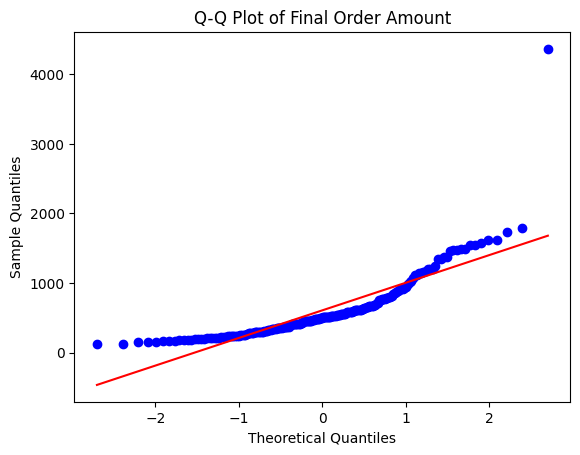

In [ ]:
# Quantile Quantile Plot for Normal Distribution
# Step 1: Import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Ensure df is loaded from the CSV
try:
    df = pd.read_csv("/content/Zomato_India_Orders_Dataset - Orders_Data.csv")
except FileNotFoundError:
    raise FileNotFoundError("Please execute your data loading cell first, or upload '/content/Zomato_India_Orders_Dataset - Orders_Data.csv'")

# Clean "Final_Amount" column: remove commas and convert to float
df["Final_Amount"] = df["Final_Amount"].astype(str).str.replace(",", "")
df["Final_Amount"] = pd.to_numeric(df["Final_Amount"], errors="coerce")

# Step 2: Remove missing values from Final Amount
order_amount = df["Final_Amount"].dropna()

# Step 3: Create the Q-Q plot
stats.probplot(order_amount, dist="norm", plot=plt)

# Step 4: Add a title
plt.title("Q-Q Plot of Final Order Amount")

# Step 5: Label the axes
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")

# Step 6: Show the plot
plt.show()

Cuisine
Pizza           34249.0
North Indian    27039.5
Biryani         26511.5
Chinese         13417.5
Burgers          9909.5
Desserts         7844.5
South Indian     2348.0
Name: Final_Amount, dtype: float64


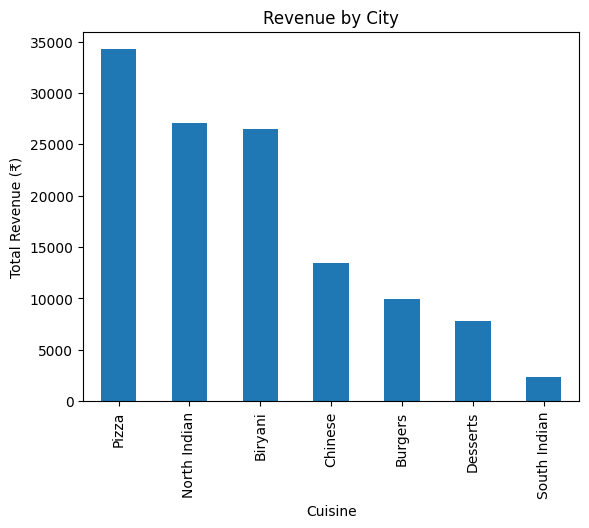

In [ ]:
# BAR CHART
import matplotlib.pyplot as plt

# Ensure Final_Amount is numeric
df["Final_Amount"] = pd.to_numeric(df["Final_Amount"].astype(str).str.replace(",", ""), errors="coerce")

# Step 1: Find total revenue for each city
Cuisine_revenue = df.groupby("Cuisine")["Final_Amount"].sum()

# Step 2: Arrange cities from highest to lowest revenue
Cuisine_revenue = Cuisine_revenue.sort_values(ascending=False)

# Step 3: Print the revenue of each city
print(Cuisine_revenue)

# Step 4: Create a bar chart
Cuisine_revenue.plot(kind="bar")

# Step 5: Add chart title and y-axis label
plt.title("Revenue by City")
plt.ylabel("Total Revenue (₹)")

# Step 6: Show the chart
plt.show()

Order_Date
2026-07    51
2026-08    63
2026-09    86
Freq: M, Name: Order_ID, dtype: int64


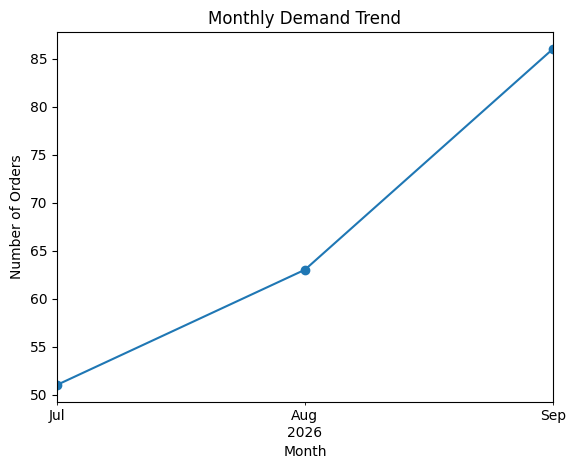

In [ ]:
# Step 1: Convert Order Date into a date format
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

# Step 2: Count the number of orders each month
monthly_orders = df.groupby(df["Order_Date"].dt.to_period("M"))["Order_ID"].count()

# Step 3: Print the monthly orders
print(monthly_orders)

# Step 4: Create a line chart
monthly_orders.plot(kind="line", marker="o")

# Step 5: Add title and labels
plt.title("Monthly Demand Trend")
plt.ylabel("Number of Orders")
plt.xlabel("Month")

# Step 6: Show the chart
plt.show()

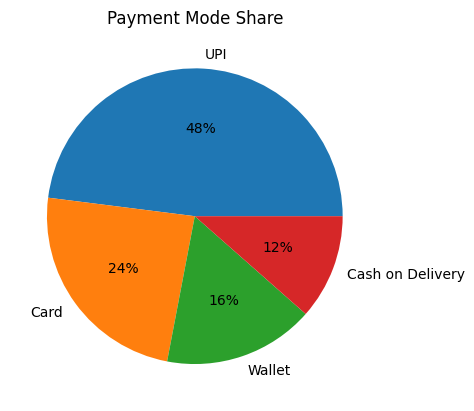

In [ ]:
#PIE CHART
# Step 1: Count each payment mode
payment_counts = df["Payment_Mode"].value_counts()

# Step 2: Create a pie chart
plt.pie(payment_counts.values, labels=payment_counts.index, autopct="%1.0f%%")

# Step 3: Add title
plt.title("Payment Mode Share")

# Step 4: Show the chart
plt.show()

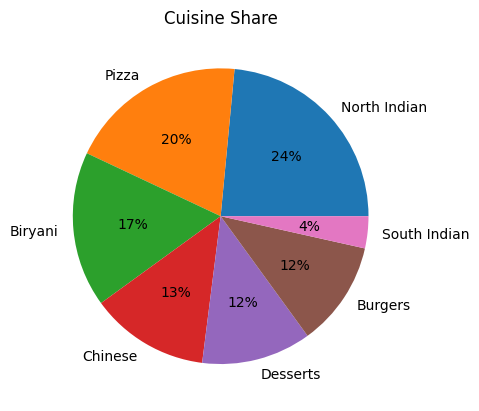

In [ ]:
#PIE CHART
# Step 1: Count each Cuisine
Cuisine_counts = df["Cuisine"].value_counts()

# Step 2: Create a pie chart
plt.pie(Cuisine_counts.values, labels=Cuisine_counts.index, autopct="%1.0f%%")

# Step 3: Add title
plt.title("Cuisine Share")

# Step 4: Show the chart
plt.show()

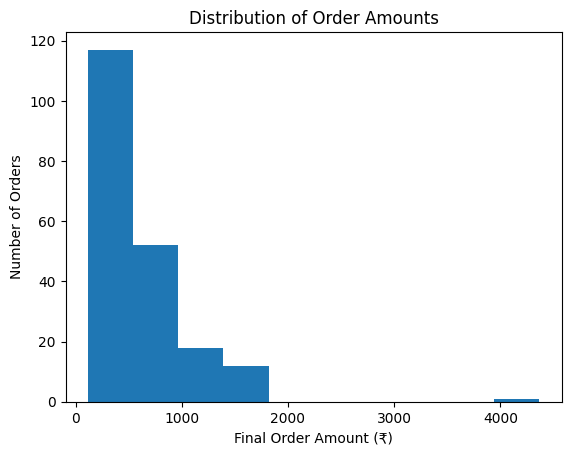

In [ ]:
# HISTOGRAM
# Step 1: Create histogram of order amounts
plt.hist(df["Final_Amount"].dropna(), bins=10)

# Step 2: Add title and labels
plt.title("Distribution of Order Amounts")
plt.xlabel("Final Order Amount (₹)")
plt.ylabel("Number of Orders")

# Step 3: Show chart
plt.show()

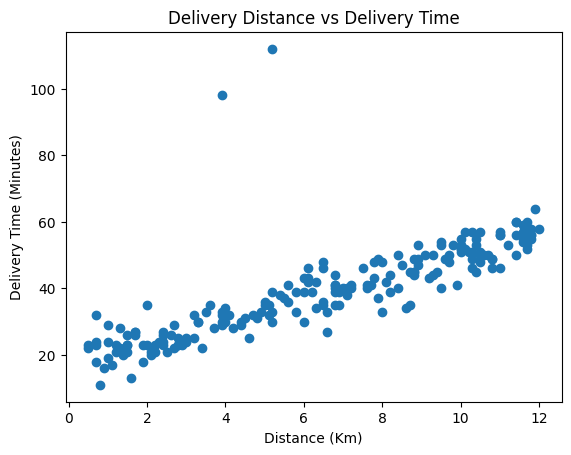

In [ ]:
#Scatter Plot
# Step 1: Create scatter plot
plt.scatter(df["Distance_Km"], df["Delivery_Time_Min"])

# Step 2: Add title and labels
plt.title("Delivery Distance vs Delivery Time")
plt.xlabel("Distance (Km)")
plt.ylabel("Delivery Time (Minutes)")

# Step 3: Show chart
plt.show()

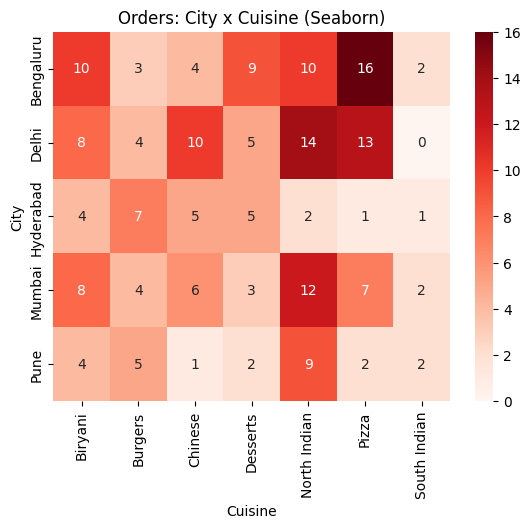

In [ ]:
# Heatmap: City x Cuisine order counts (the dark/zero cells show gaps)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the city cuisine variable using a cross-tabulation
city_cuisine = pd.crosstab(df["City"], df["Cuisine"])

# Plot heatmap
sns.heatmap(city_cuisine, annot=True, fmt="d", cmap="Reds")
plt.title("Orders: City x Cuisine (Seaborn)")
plt.show()

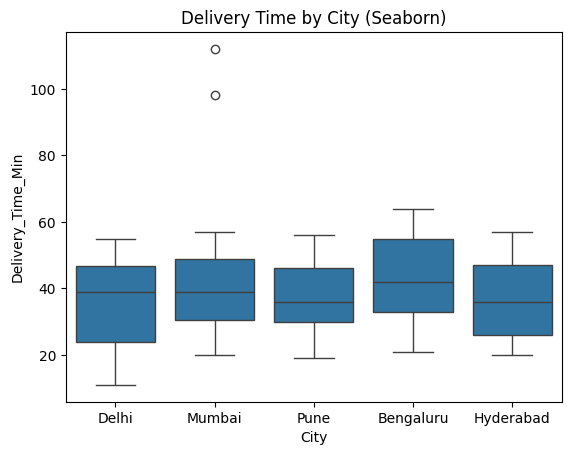

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot
sns.boxplot(data=df, x="City", y="Delivery_Time_Min")
plt.title("Delivery Time by City (Seaborn)")
plt.show()

LECTURE 7

In [3]:
#Method 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

sns.set_style("whitegrid")
file_path = "/content/SkyBridge_Airline_Data (1).xlsx"

df = pd.read_excel(file_path, sheet_name="Unclean_Data")
df.head()


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


In [4]:
#Method 2
raw = pd.read_excel("/content/SkyBridge_Airline_Data (1).xlsx", sheet_name="Unclean_Data")
# The 9 numeric columns we will study
num_cols = ["Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration _Min", "Fuel_Cost", "Ancillary_Revenue", "Baggage_Complaints", "Customer Rating", "Crew_Overtime Hours"]
print("Rows and columns:", raw.shape)
raw.head()


Rows and columns: (120, 12)


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


STEP 1 DETECETING UNUSUAL VALUES

In [5]:
raw.isnull().sum()


,0
Date,0
Flight_ID,0
Route,4
Passengers,5
Ticket_Price,7
Delay_Minutes,6
Flight_Duration_Min,4
Fuel_Cost,6
Ancillary_Revenue,6
Baggage_Complaints,5


In [6]:
# percent of missing values
total_blank = raw.isnull().sum().sum()
print("Blank Cells :", total_blank)

blank_percentage = round((total_blank / raw.size) * 100, 1)
print(f"Blank % : {blank_percentage}%")

rows_with_blanks = raw.isnull().any(axis=1).sum()
print(f"Rows with at least one blank: {rows_with_blanks} out of {len(raw)}")

Blank Cells : 58
Blank % : 4.0%
Rows with at least one blank: 48 out of 120


Heatplot for missing values

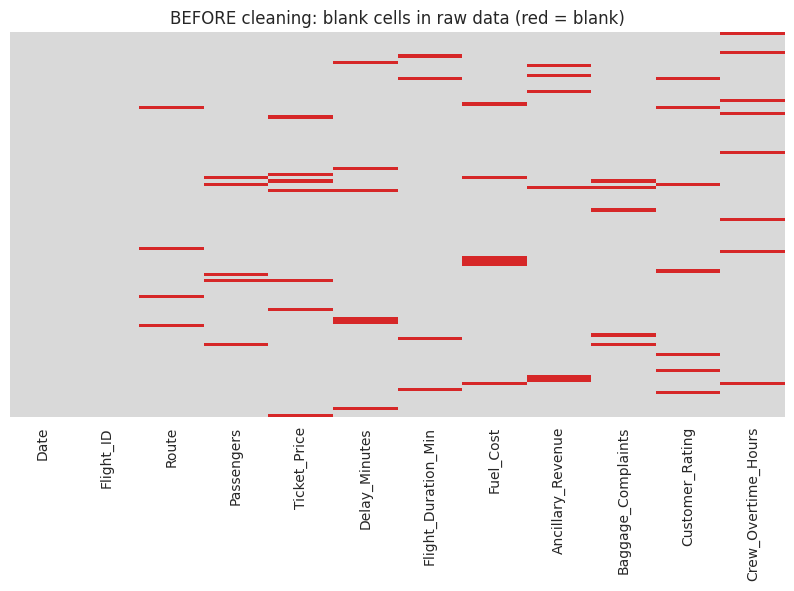

In [7]:
from matplotlib.colors import ListedColormap

colors = ListedColormap(["#d9d9d9", "#d62728"])
plt.figure(figsize=(10, 5))
sns.heatmap(raw.isnull(), cmap=colors, cbar=False, yticklabels=False)
plt.title("BEFORE cleaning: blank cells in raw data (red = blank)")
plt.show()


Descriptive Statistics

In [10]:
# Correcting the list of column names to match the dataset exactly
num_cols = [
    "Passengers",
    "Ticket_Price",
    "Delay_Minutes",
    "Flight_Duration_Min",
    "Fuel_Cost",
    "Ancillary_Revenue",
    "Baggage_Complaints",
    "Customer_Rating",
    "Crew_Overtime_Hours"
]

raw[num_cols].describe().round(1)

,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,115.0,113.0,114.0,116.0,114.0,114.0,115.0,113.0,112.0
mean,155.0,6374.3,19.4,157.2,511.2,59615.8,3.1,4.2,6.5
std,13.6,4836.7,35.9,30.0,78.0,11182.3,2.4,0.6,2.8
min,120.0,4800.0,-45.0,122.0,398.0,37900.0,0.0,3.5,2.8
25%,147.0,5550.0,9.0,132.0,433.0,54425.0,2.0,4.0,5.2
50%,155.0,5900.0,16.0,165.0,530.0,58800.0,3.0,4.1,6.1
75%,163.0,6300.0,23.8,170.0,563.8,64225.0,4.0,4.3,7.3
max,215.0,57000.0,380.0,410.0,980.0,148000.0,19.0,9.4,31.5


Gap between mean and median

In [11]:
#Gap between mean and median
gap = pd.DataFrame({
    "Mean": raw[num_cols].mean(),
    "Median": raw[num_cols].median()
})
gap["Gap %"] = ((gap["Mean"] - gap["Median"]) / gap["Median"] * 100).round(1)
gap.round(1)

,Mean,Median,Gap %
Passengers,155.0,155.0,-0.0
Ticket_Price,6374.3,5900.0,8.0
Delay_Minutes,19.4,16.0,21.2
Flight_Duration_Min,157.2,165.0,-4.7
Fuel_Cost,511.2,530.0,-3.5
Ancillary_Revenue,59615.8,58800.0,1.4
Baggage_Complaints,3.1,3.0,3.5
Customer_Rating,4.2,4.1,1.8
Crew_Overtime_Hours,6.5,6.1,6.2


Rules for the numeric values

In [12]:
rules = {
    "Passengers":        (0, 180),    # aircraft has 180 seats
    "Ticket_Price":      (1000, 20000), # domestic low-cost fare in INR
    "Delay_Minutes":     (0, 600),    # a delay cannot be negative
    "Flight_Duration_Min": (60, 240), # domestic sector
    "Customer_Rating":   (1, 5),      # rating scale 1 to 5
}

for col, (low, high) in rules.items():
    bad = raw[(raw[col] < low) | (raw[col] > high)]
    print(col, "-> impossible values:", len(bad))
    if len(bad) > 0:
        print(bad[["Date", "Flight_ID", col]].to_string(index=False))
    print()

Passengers -> impossible values: 1
      Date Flight_ID  Passengers
2026-02-07    SB-038       215.0

Ticket_Price -> impossible values: 1
      Date Flight_ID  Ticket_Price
2026-01-15    SB-015       57000.0

Delay_Minutes -> impossible values: 1
      Date Flight_ID  Delay_Minutes
2026-01-23    SB-023          -45.0

Flight_Duration_Min -> impossible values: 1
      Date Flight_ID  Flight_Duration_Min
2026-04-02    SB-092                410.0

Customer_Rating -> impossible values: 1
      Date Flight_ID  Customer_Rating
2026-03-18    SB-077              9.4



Step 4 Time series plot

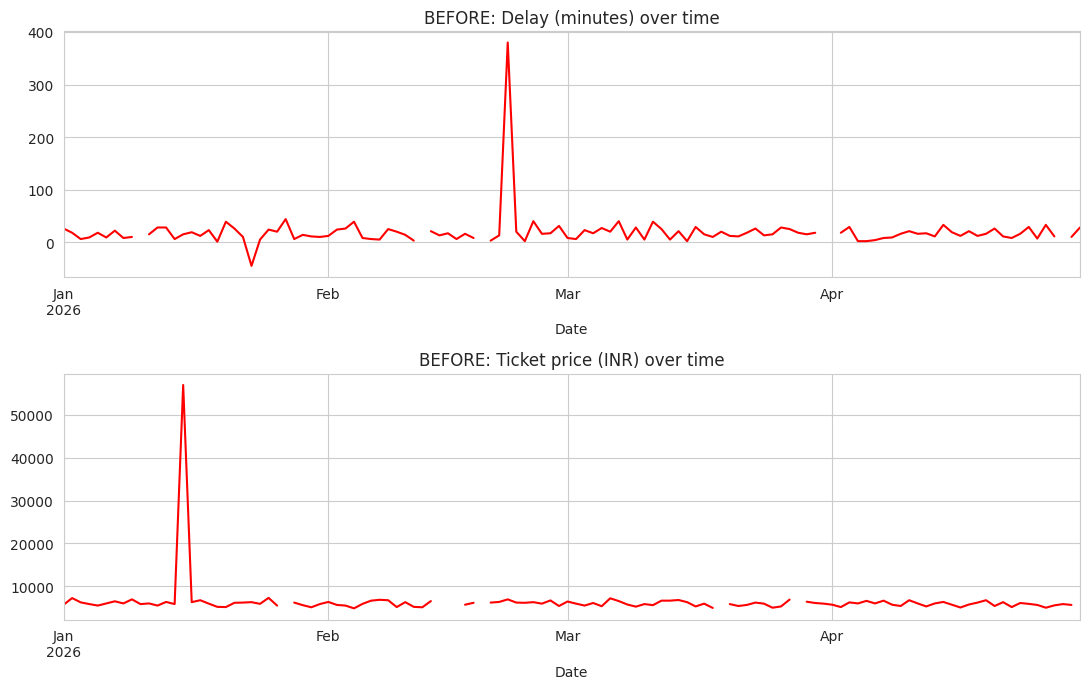

In [13]:

ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

ts_raw["Delay_Minutes"].plot(ax=axes[0], color="red", title="BEFORE: Delay (minutes) over time")
ts_raw["Ticket_Price"].plot(ax=axes[1], color="red", title="BEFORE: Ticket price (INR) over time")

plt.tight_layout()
plt.show()

Box plot

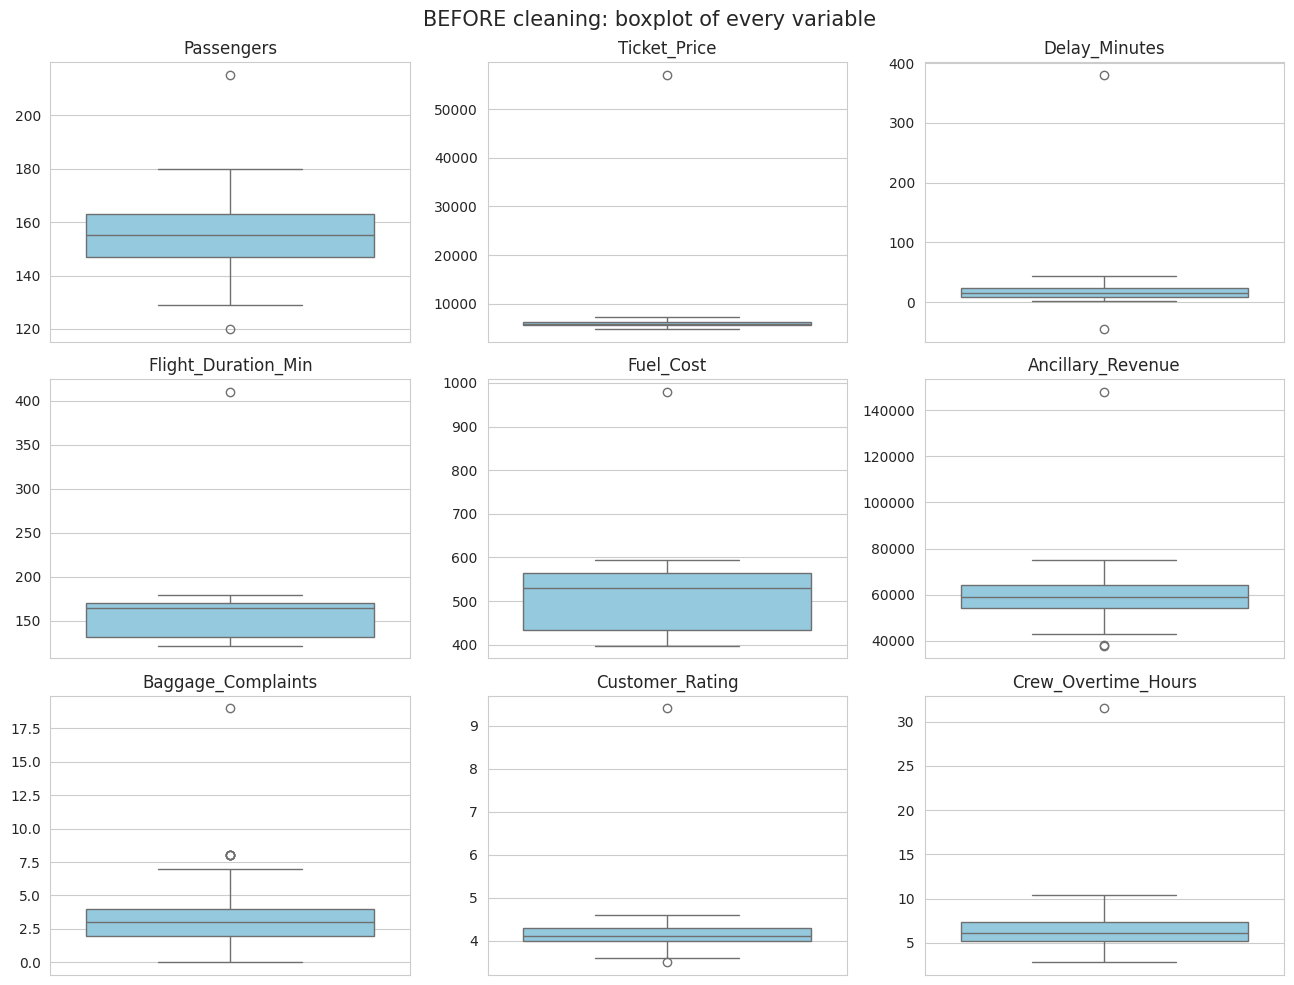

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

def show_boxplots(data, title):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")

Retaining removing and capping outlier

In [16]:
#REMOVING EXTREME VALUES

df = raw.copy()

# Find ratings below 1 or above 5
bad_values = (df["Customer_Rating"] < 1) | (df["Customer_Rating"] > 5)

# Count unusual ratings
print("Unusual ratings:", bad_values.sum())

# Replace unusual ratings with missing values
df.loc[bad_values, "Customer_Rating"] = np.nan

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())

print("Missing cells after:", df.isnull().sum().sum())

Unusual ratings: 1
Missing cells before: 58
Missing cells after: 59
